This workflow will be:
```
Input "question" from user
            |
            |
       LLM_QA node
            |
            |
     LLM_summary node
            |
            |
           END
```

In [1]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph
from langchain_openai import ChatOpenAI

In [2]:
class QAState(TypedDict):
    question: str
    answer: str
    summary: str

In [3]:
llm = ChatOpenAI(
    model='local qwen 3.5:4b-q4',
    base_url='http://127.0.0.1:8080/v1',
    api_key='not needed' # type: ignore
)

In [4]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate

In [5]:
answer_template = PromptTemplate(
    template='''
    You are a helpful question answering bot. Answer the asked question in a precise way. Include details you think might be helpful
    Question:
    {question}
''',
input_variables=['question'],
validate_template=True
)

summary_template = PromptTemplate(
    template='''
    You are a answer summarising bot. Summarise the given content to around 50-80 words.
    Content:
    {content}
''',
input_variables=['content'],
validate_template=True
)


answer_chain = answer_template | llm | StrOutputParser()
summary_chain = summary_template | llm | StrOutputParser()

In [6]:
def llm_qa(state: QAState) -> QAState:
    question = state['question']
    answer = answer_chain.invoke({'question': question})
    state['answer'] = answer

    return state

In [7]:
def llm_summary(state: QAState) -> QAState:
    content = state['answer']
    summary = summary_chain.invoke({'content': content})
    state['summary'] = summary

    return state

In [8]:
graph = StateGraph(QAState)

graph.add_node('llm_qa', llm_qa)
graph.add_node('llm_summary', llm_summary)

graph.add_edge(START, 'llm_qa')
graph.add_edge('llm_qa', 'llm_summary')
graph.add_edge('llm_summary', END)

workflow = graph.compile()

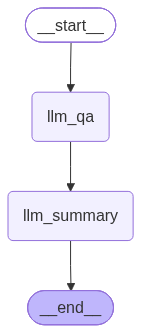

In [9]:
workflow

In [12]:
question = input('Ask any question')

initial_state = {'question':question}

output_state = workflow.invoke(initial_state) # type: ignore

In [13]:
from IPython.display import display, Markdown


for key, value in output_state.items():
    display(Markdown(f'{key.capitalize()}:\n{value}\n\n---'))

Question:
What in your opinion is the best Bethesda IP and why is it The Elder Scrolls?

---

Answer:
It is important to clarify a significant factual premise in your question: **The Elder Scrolls is not the best Bethesda IP in my opinion, nor is it the only "best" one.** In fact, **The Elder Scrolls** is generally considered the crown jewel of the Bethesda series, while **Fallout** is widely regarded as their most culturally impactful and critically acclaimed standalone franchise outside of *Skyrim*.

Here is a detailed breakdown of why *The Elder Scrolls* holds such a high place, along with a comparison to Bethesda's other major IPs to provide context on what is actually "best" depending on the criteria used.

### Why The Elder Scrolls is Often Considered the "Best"

While "best" is subjective, *The Elder Scrolls* (specifically the fifth game, *Skyrim*, and the fourth, *Oblivion*) is frequently cited as the superior intellectual property for several structural and artistic reasons:

1.  **Unparalleled World Immersion**
    Bethesda's "Creation Engine" allows for a level of detail and freedom in *The Elder Scrolls* that few other RPGs match. The world feels truly alive because of:
    *   **Procedural Generation:** Every town, forest, and mountain range is unique.
    *   **Living Economies:** NPCs have schedules, jobs, relationships, and react to your actions over time.
    *   **Atmosphere:** The game masterfully uses lighting, weather systems, and soundscapes to create a sense of scale and danger that makes the world feel dangerous and real, even when exploring a castle or a quiet village.

2.  **The "Open-Ended" Narrative Design**
    Bethesda's philosophy in *The Elder Scrolls* is built on the idea that **you are the protagonist**.
    *   Unlike *Fallout* (which has a strong, driving narrative about survival and nuclear apocalypse) or *Dragon Age* (which has a rigid story-driven structure), *The Elder Scrolls* offers a sandbox where your choices matter, but they don't always dictate a singular ending.
    *   This creates a sense of agency that few games replicate. You can be a thief, a dragon, a pacifist, or a dictator, and the game adapts to that.

3.  **Cultural Impact and Longevity**
    *   *The Elder Scrolls IV: Oblivion* and *V* have been running for over 15 years without a major reboot, proving their longevity.
    *   The lore is deep, consistent, and expanding (through books, mods, and DLCs). It has created a culture of fan theories, creative writing, and modding that rivals or exceeds that of almost any other game IP.
    *   *Skyrim* remains a cultural touchstone, often cited by critics and players alike as the peak of the genre.

### Comparison with Other Bethesda IPs

To answer the "best" question objectively, we must look at Bethesda's other flagship IP: **The Fallout Series**.

*   **Fallout 3 & Fallout: New Vegas**: These games are often praised for having the **best narratives and dialogue**. If you prefer a story where every character feels distinct, the plot is tight, and the world-building feels grounded in history and politics, *Fallout* often beats *The Elder Scrolls*.
*   **The Elder Scrolls vs. Fallout**: *The Elder Scrolls* offers more freedom and exploration; *Fallout* offers better writing and a more cohesive narrative. However, *The Elder Scrolls* generally wins on **world-building scope** and **player agency**.

### Conclusion: Is The Elder Scrolls the Best?

**Yes, if your definition of "best" is the most immersive open-world experience, the greatest freedom of play, and the most expansive world-building.**

*The Elder Scrolls* IP is the foundation of Bethesda's identity. While *Fallout* has a stronger story, *The Elder Scrolls* has a stronger *world*. The reason it is often called the "best" is that it successfully combines massive scale with a sense of intimacy, allowing players to feel like they are truly living in a living, breathing world where they are the main character.

**Verdict:**
*   **Best for Immersion & Freedom:** *The Elder Scrolls* (specifically *Oblivion* and *Skyrim*).
*   **Best for Narrative & Dialogue:** *Fallout* (specifically *New Vegas* and *3*).
*   **Overall Cultural Phenomenon:** It is a tie, but *The Elder Scrolls* usually takes the lead in terms of raw world scale and player freedom.

---

Summary:
The Elder Scrolls (specifically *Skyrim* and *Oblivion*) is widely considered the "crown jewel" of Bethesda's intellectual properties, often surpassing *Fallout* in immersion, world-building, and player freedom. While *Fallout* excels in narrative depth and dialogue, *The Elder Scrolls* offers unparalleled open-world exploration and a living, breathing ecosystem. Ultimately, *The Elder Scrolls* is best defined by its massive scale and unique agency, though *Fallout* remains a strong contender for storytelling.

---